# Báo cáo: Nhận diện hành động người–vật (V-COCO, 6 lớp) bằng đặc trưng thủ công + ML cổ điển

Pipeline: `01_extract_features.py` → `02_train_select.py` → `03_final_test.py` → notebook này (chạy tất cả bằng `run_all.sh` ở thư mục gốc).

Notebook đọc kết quả của **một phiên bản** `data/results/<VERSION>/` (đặt ở ô dưới hoặc biến môi trường `RUN_VERSION`). Muốn xem phiên bản cũ thì đặt `VERSION` cũ rồi chạy lại notebook; bảng các phiên bản ở README.

- **4 đặc trưng cơ bản**: HOG (dáng người), LBP (kết cấu), Color Histogram HSV (màu/bối cảnh), SIFT + Bag of Visual Words (chi tiết cục bộ).
- **Đặc trưng bổ sung**: `geom` (hình học bbox người), `sift_spm` (BoVW + spatial pyramid 1x1+2x2), `upper` (HOG + BoVW vùng 40% phía trên: đầu/tay gần mặt), `gist` (năng lượng Gabor 4 tỉ lệ × 8 hướng trên lưới 4x4), `skin` (vị trí vùng da YCrCb).
- **Phối hợp**: `fused` (4 cơ bản), `combo_local` (sift_spm + sift_upper + color + geom + skin), `fused_all` (tất cả).
- **Mô hình**: Logistic Regression, SVM (RBF), Random Forest, XGBoost — cân bằng lớp bằng `class_weight` (XGBoost: `sample_weight`).
- **Đánh giá**: macro-F1 + recall từng lớp (không dùng accuracy vì `unknown` chiếm ~65%). Chọn mô hình trên **val**, test chỉ báo cáo.

In [1]:
import sys, json
sys.path.insert(0, '.')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, cv2, joblib
import config as C
from data_utils import load_labels, read_image
from features import hog, lbp_image, sift_descriptors, skin_mask, gabor_bank
import features as F
from models import FEATURE_SETS, blocks, eval_metrics

import os
import versioning as V
# Phiên bản kết quả cần xem (data/results/<VERSION>/). Có thể truyền qua biến môi trường RUN_VERSION.
VERSION = os.environ.get('RUN_VERSION', 'r04')
RES_DIR = V.result_dir(VERSION)
FEAT_DIR = V.feat_dir(V.read_run_info(RES_DIR)['02_train_select'][0]['args']['feat_version'])
# Dữ liệu mà phiên bản đặc trưng đã dùng (bản cũ không ghi -> mặc định trong config.py)
from data_utils import set_labels_csv
_fi = V.read_run_info(FEAT_DIR).get('01_extract_features', [{}])[0]
if _fi.get('labels_csv'): set_labels_csv(_fi['labels_csv'], _fi.get('data_dir'))
print('Kết quả:', RES_DIR.relative_to(C.ROOT), '| Đặc trưng:', FEAT_DIR.relative_to(C.ROOT), '| Dữ liệu:', C.LABELS_CSV.relative_to(C.ROOT))
plt.rcParams['figure.dpi'] = 100

Kết quả: data/results/r04 | Đặc trưng: data/features/f03 | Dữ liệu: data/train_test_split/labels_split_unk3000.csv


## 1. Khám phá dữ liệu

split,train,val,test,train_%,val_%,test_%
label,,,,,,
hold,1916,384,401,21.1,20.4,21.3
ride,2053,422,389,22.6,22.5,20.6
eat/drink,1078,200,208,11.9,10.6,11.0
talk_on_phone,920,192,215,10.1,10.2,11.4
work_on_computer,1015,224,216,11.2,11.9,11.5
unknown,2087,456,457,23.0,24.3,24.2


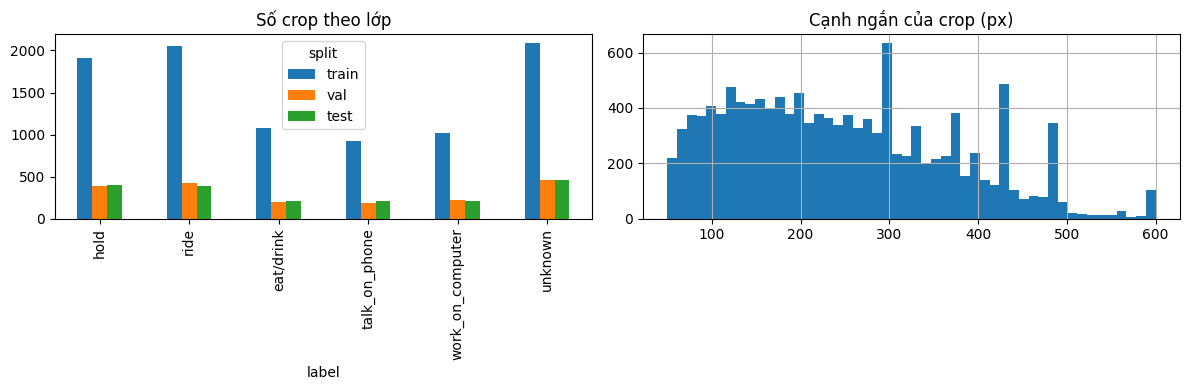

In [2]:
df = load_labels()
tab = pd.crosstab(df['label'], df['split'])[C.SPLITS].reindex(C.CLASSES)
display(tab.assign(**{f'{s}_%': (tab[s] / tab[s].sum() * 100).round(1) for s in C.SPLITS}))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
tab.plot.bar(ax=axes[0]); axes[0].set_title('Số crop theo lớp')
df['short_side'] = df[['crop_w', 'crop_h']].min(axis=1)
df['short_side'].clip(upper=600).hist(bins=50, ax=axes[1]); axes[1].set_title('Cạnh ngắn của crop (px)')
plt.tight_layout()

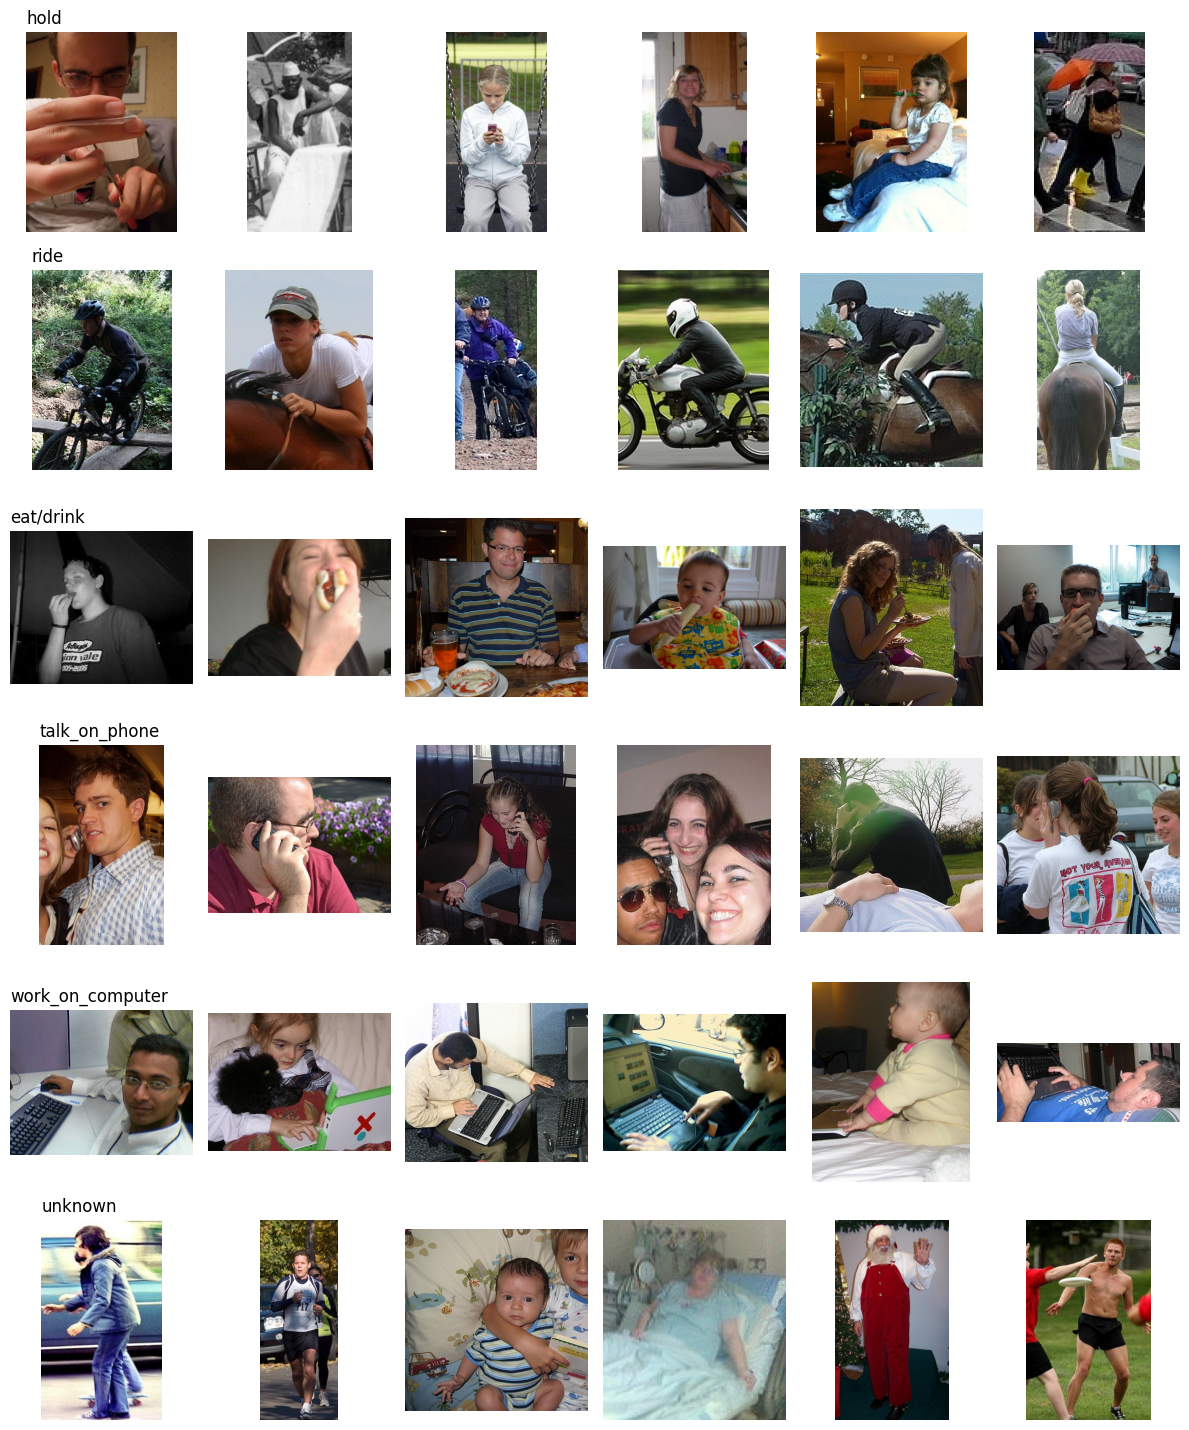

In [3]:
fig, axes = plt.subplots(len(C.CLASSES), 6, figsize=(12, 2.4 * len(C.CLASSES)))
tr = df[df.split == 'train']
for i, c in enumerate(C.CLASSES):
    sub = tr[tr.label == c].sample(min(6, (tr.label == c).sum()), random_state=0)
    for j in range(6):
        ax = axes[i, j]; ax.axis('off')
        if j < len(sub):
            ax.imshow(cv2.cvtColor(read_image(sub.iloc[j]['path']), cv2.COLOR_BGR2RGB))
        if j == 0: ax.set_title(c, loc='left')
plt.tight_layout()

## 2. Minh họa 4 loại đặc trưng

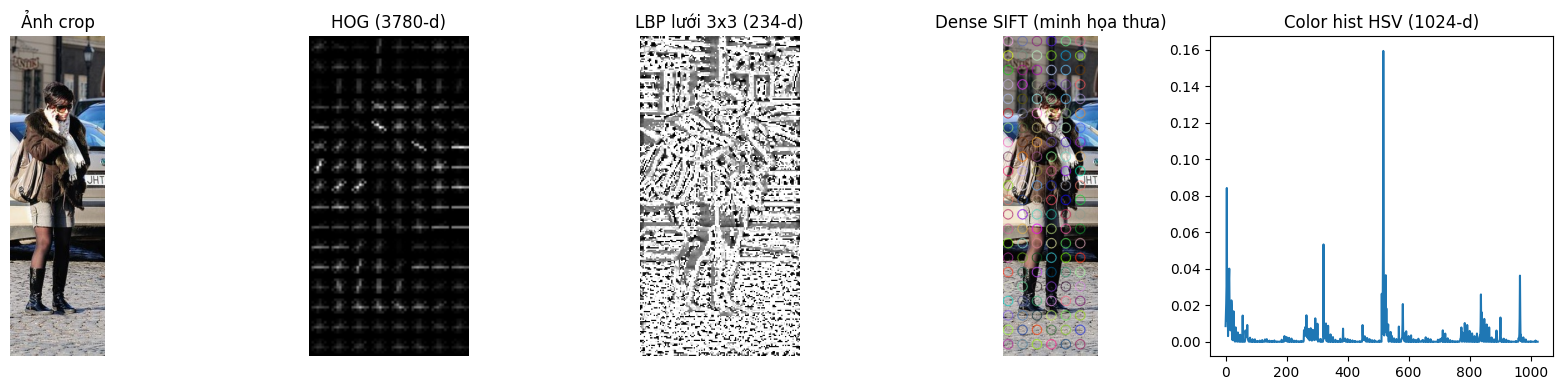

In [4]:
sample = tr[tr.label == 'talk_on_phone'].iloc[0]['path'] if (tr.label == 'talk_on_phone').any() else tr.iloc[0]['path']
img = read_image(sample)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
_, hog_img = hog(cv2.resize(gray, C.HOG_SIZE), orientations=9, pixels_per_cell=(8, 8),
                 cells_per_block=(2, 2), block_norm='L2-Hys', visualize=True)
lbp = lbp_image(img)
kps = [cv2.KeyPoint(float(x), float(y), C.SIFT_SIZE) for y in range(8, gray.shape[0] - 8, 24) for x in range(8, gray.shape[1] - 8, 24)]
sift_vis = cv2.drawKeypoints(cv2.cvtColor(img, cv2.COLOR_BGR2RGB), kps, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

fig, axes = plt.subplots(1, 5, figsize=(17, 4))
axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); axes[0].set_title('Ảnh crop')
axes[1].imshow(hog_img, cmap='gray'); axes[1].set_title(f'HOG ({len(F.hog_feat(img))}-d)')
axes[2].imshow(lbp, cmap='gray'); axes[2].set_title(f'LBP lưới 3x3 ({len(F.lbp_feat(img))}-d)')
axes[3].imshow(sift_vis); axes[3].set_title('Dense SIFT (minh họa thưa)')
axes[4].plot(F.color_feat(img)); axes[4].set_title(f'Color hist HSV ({len(F.color_feat(img))}-d)')
for a in axes[:4]: a.axis('off')
plt.tight_layout()

Các đặc trưng bổ sung: vùng thân trên, GIST (đáp ứng Gabor), skin mask, và các khối của SIFT spatial pyramid.

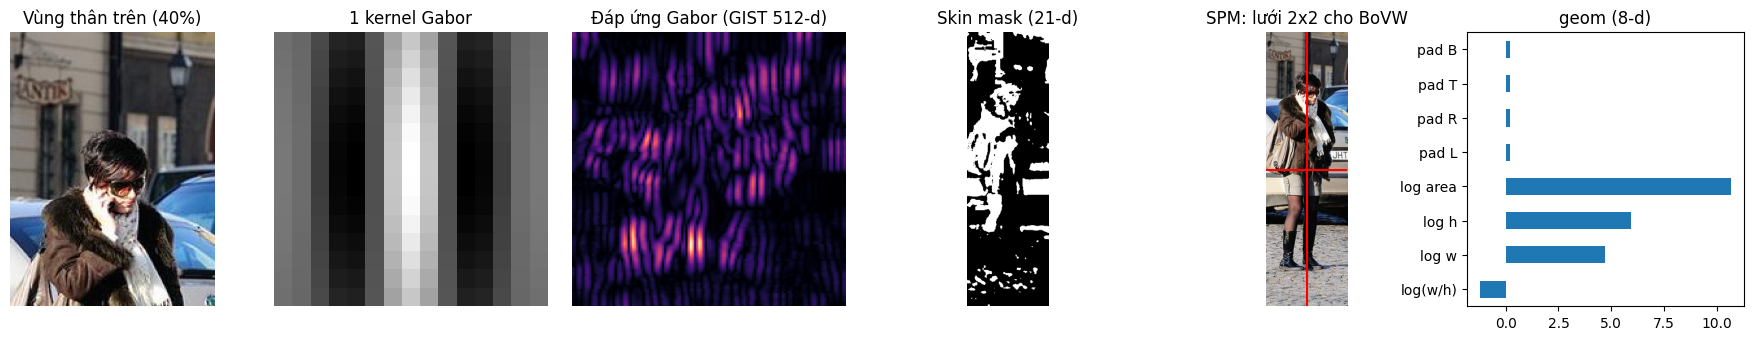

In [5]:
top = img[: int(img.shape[0] * C.UPPER_FRAC)]
g128 = cv2.resize(gray, (C.GIST_SIZE, C.GIST_SIZE)).astype(np.float32) / 255
bank = gabor_bank()
fig, axes = plt.subplots(1, 6, figsize=(18, 3.5))
axes[0].imshow(cv2.cvtColor(top, cv2.COLOR_BGR2RGB)); axes[0].set_title(f'Vùng thân trên ({C.UPPER_FRAC:.0%})')
axes[1].imshow(bank[C.GIST_ORIENT * 2], cmap='gray'); axes[1].set_title('1 kernel Gabor')
axes[2].imshow(np.abs(cv2.filter2D(g128, cv2.CV_32F, bank[C.GIST_ORIENT * 2])), cmap='magma'); axes[2].set_title(f'Đáp ứng Gabor (GIST {len(F.gist_feat(img))}-d)')
axes[3].imshow(skin_mask(img), cmap='gray'); axes[3].set_title(f'Skin mask ({len(F.skin_feat(img))}-d)')
axes[4].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); axes[4].axhline(img.shape[0] / 2, c='r'); axes[4].axvline(img.shape[1] / 2, c='r'); axes[4].set_title('SPM: lưới 2x2 cho BoVW')
geo = pd.Series(F.geom_feat(tr[tr.path == sample].iloc[0]), index=['log(w/h)', 'log w', 'log h', 'log area', 'pad L', 'pad R', 'pad T', 'pad B'])
geo.plot.barh(ax=axes[5]); axes[5].set_title('geom (8-d)')
for a in axes[:5]: a.axis('off')
plt.tight_layout()

## 3. Kết quả chọn mô hình trên val (12 bộ đặc trưng × 4 mô hình)

,feature,model,dim,val_macro_f1,val_accuracy,val_macro_precision,val_macro_recall (= balanced acc),val_weighted_f1,best_params,time_s
0,clip,svm,512,0.878451,0.881257,0.884401,0.873512,0.881989,"{""clf__C"": 10, ""clf__gamma"": ""scale""}",46.9
1,clip,xgb,512,0.870040,0.872204,0.875383,0.867126,0.873627,"{""clf__learning_rate"": 0.1, ""clf__max_depth"": ...",102.1
2,clip,logreg,512,0.869777,0.875399,0.864786,0.876089,0.875427,"{""clf__C"": 0.01}",3.5
3,clip,rf,512,0.846648,0.844515,0.872477,0.833457,0.848015,"{""clf__max_depth"": null, ""clf__min_samples_lea...",99.0
4,clip,clip_zs,512,0.604621,0.569223,0.665485,0.635698,0.531313,"{""clf__T"": 0.6}",0.3
5,sift,svm,500,0.480345,0.507987,0.480477,0.491717,0.507048,"{""clf__C"": 1, ""clf__gamma"": ""scale""}",109.5
6,sift,xgb,500,0.449024,0.484026,0.452382,0.451093,0.481387,"{""clf__learning_rate"": 0.1, ""clf__max_depth"": ...",58.5
7,sift,logreg,500,0.429787,0.456869,0.429362,0.446369,0.456826,"{""clf__C"": 0.01}",0.8
8,sift,rf,500,0.415408,0.465389,0.437298,0.421241,0.452891,"{""clf__max_depth"": null, ""clf__min_samples_lea...",32.6


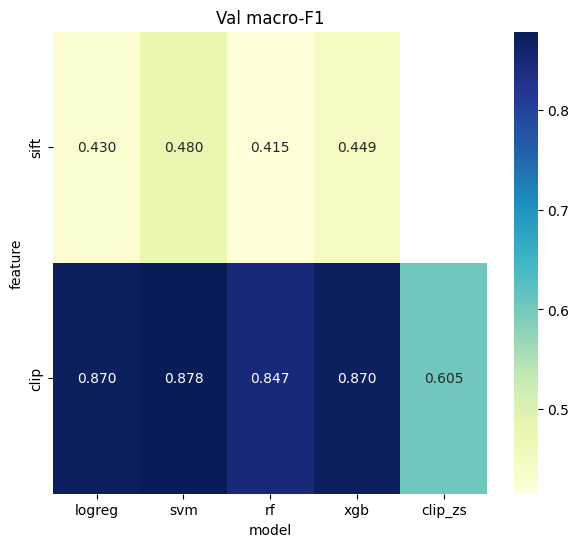

In [6]:
val = pd.read_csv(RES_DIR / 'val_results.csv')
piv = val.pivot(index='feature', columns='model', values='val_macro_f1').reindex([f for f in FEATURE_SETS if f in set(val.feature)])
piv = piv[[m for m in ['logreg', 'svm', 'rf', 'xgb', 'clip_zs'] if m in piv.columns]]
plt.figure(figsize=(7, 6)); sns.heatmap(piv, annot=True, fmt='.3f', cmap='YlGnBu'); plt.title('Val macro-F1')
# Macro-F1 là chỉ số chọn mô hình; accuracy / precision / weighted F1 để tham khảo (có từ r03)
cols = [c for c in ['feature', 'model', 'dim', 'val_macro_f1', 'val_accuracy', 'val_macro_precision', 'val_balanced_acc',
                    'val_weighted_f1', 'best_params', 'time_s'] if c in val]
display(val.sort_values('val_macro_f1', ascending=False)[cols].rename(columns={'val_balanced_acc': 'val_macro_recall (= balanced acc)'}))
if 'val_accuracy' not in val:
    print('Phiên bản này chỉ ghi macro-F1, balanced accuracy và recall trên val; accuracy, precision, F1 từng lớp có từ r03.')

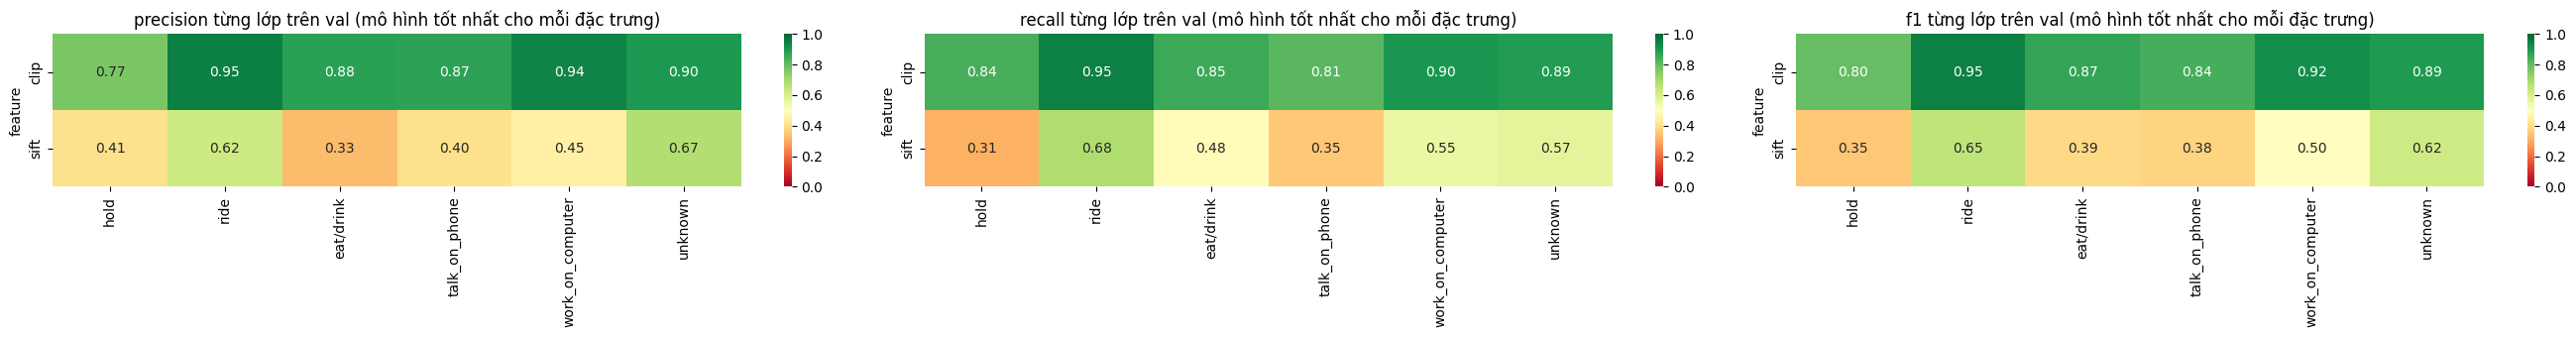

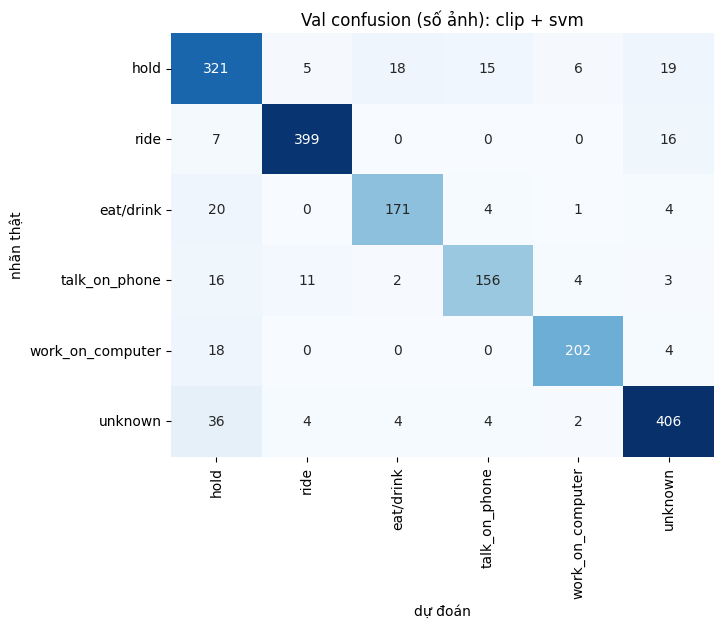

In [7]:
rec_cols = [f'recall_{c}' for c in C.CLASSES]
best_feat = val.sort_values('val_macro_f1', ascending=False).groupby('feature').head(1).set_index('feature')
# Precision / recall / F1 từng lớp trên val (mô hình tốt nhất cho mỗi đặc trưng); precision, F1 có từ r03
kinds = [k for k in ['precision', 'recall', 'f1'] if f'{k}_{C.CLASSES[0]}' in val]
fig, axes = plt.subplots(1, len(kinds), figsize=(9 * len(kinds), 0.5 * len(best_feat) + 2.5), squeeze=False)
for ax, k in zip(axes[0], kinds):
    sns.heatmap(best_feat[[f'{k}_{c}' for c in C.CLASSES]].rename(columns=lambda s: s[len(k) + 1:]), annot=True, fmt='.2f',
                cmap='RdYlGn', vmin=0, vmax=1, ax=ax)
    ax.set_title(f'{k} từng lớp trên val (mô hình tốt nhất cho mỗi đặc trưng)')
plt.tight_layout()
# Ma trận nhầm lẫn trên val (số ảnh) của cấu hình tốt nhất trên val; cần val_pred_*.npy (có từ r03)
from sklearn.metrics import confusion_matrix
vb = val.sort_values('val_macro_f1', ascending=False).iloc[0]
vp = RES_DIR / f'val_pred_{vb.feature}_{vb.model}.npy'
if vp.exists():
    yva = np.load(FEAT_DIR / 'y_val.npy')
    cm = pd.DataFrame(confusion_matrix(yva, np.load(vp), labels=range(len(C.CLASSES))), index=C.CLASSES, columns=C.CLASSES)
    plt.figure(figsize=(7, 5.5)); sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.xlabel('dự đoán'); plt.ylabel('nhãn thật'); plt.title(f'Val confusion (số ảnh): {vb.feature} + {vb.model}')
else:
    print('Phiên bản này chưa lưu dự đoán trên val (val_pred_*.npy, có từ r03): chưa vẽ được confusion matrix trên val.')

,param_clf__T,val_macro_f1,mean_fit_time
0,0.0,0.5619,0.0060
1,0.5,0.6032,0.0064
2,0.6,0.6046,0.0045
3,0.7,0.6035,0.0073
4,0.8,0.5993,0.0060
5,0.9,0.5947,0.0039


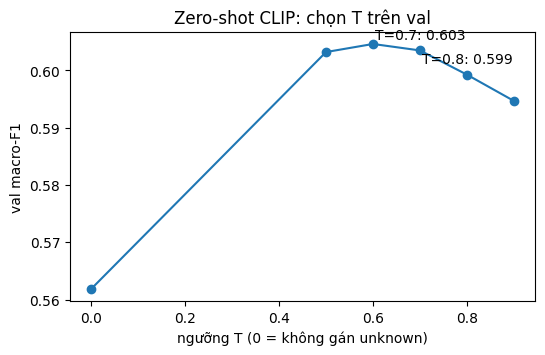

In [8]:
# Zero-shot CLIP: macro-F1 trên val theo ngưỡng T (xác suất softmax cao nhất < T -> unknown); T chọn trên val
gz = RES_DIR / 'grid_clip_clip_zs.csv'
if gz.exists():
    g = pd.read_csv(gz).sort_values('param_clf__T')
    fig, ax = plt.subplots(figsize=(6, 3.5))
    ax.plot(g.param_clf__T, g.val_macro_f1, 'o-')
    for T in (0.7, 0.8):
        r = g[np.isclose(g.param_clf__T, T)]
        if len(r): ax.annotate(f'T={T}: {r.val_macro_f1.iloc[0]:.3f}', (T, r.val_macro_f1.iloc[0]), textcoords='offset points', xytext=(0, 8), ha='center')
    ax.set_xlabel('ngưỡng T (0 = không gán unknown)'); ax.set_ylabel('val macro-F1'); ax.set_title('Zero-shot CLIP: chọn T trên val')
    display(g.round(4))
else:
    print('Phiên bản này không có zero-shot CLIP (clip_zs).')


## 4. Kết quả cuối trên test

In [9]:
te = pd.read_csv(RES_DIR / 'test_results.csv')
yte = np.load(FEAT_DIR / 'y_test.npy')
# Tính lại chỉ số từ test_pred_*.npy: phiên bản cũ (chưa có cột accuracy / precision) cũng hiển thị đủ
preds = {(r.feature, r.model): np.load(RES_DIR / f'test_pred_{r.feature}_{r.model}.npy') for r in te.itertuples()}
met = pd.DataFrame([{'feature': f, 'model': m, **eval_metrics(yte, p, 'test')} for (f, m), p in preds.items()])
te = te.drop(columns=[c for c in met if c in te and c not in ('feature', 'model')]).merge(met, on=['feature', 'model'])
# Macro-F1 là chỉ số chính; accuracy chỉ để tham khảo vì unknown chiếm đa số. Macro recall = balanced accuracy
if 'group' not in te: te['group'] = 'handcrafted'   # phiên bản cũ chỉ có đặc trưng thủ công
display(te[['group', 'feature', 'model', 'val_macro_f1', 'test_macro_f1', 'test_accuracy', 'test_macro_precision',
            'test_balanced_acc', 'test_weighted_f1', 'is_best_on_val']]
        .rename(columns={'test_balanced_acc': 'test_macro_recall (= balanced acc)'}).round(4))
# Precision / recall / F1 từng lớp của mọi cấu hình đã test
per = pd.concat({f'{r.feature}+{r.model}': pd.DataFrame({k: [r[f'{k}_{c}'] for c in C.CLASSES] for k in ('precision', 'recall', 'f1')},
                                                        index=C.CLASSES) for _, r in te.iterrows()}, axis=1)
display(per.round(3))
print((RES_DIR / 'test_report.txt').read_text())

,group,feature,model,val_macro_f1,test_macro_f1,test_accuracy,test_macro_precision,test_macro_recall (= balanced acc),test_weighted_f1,is_best_on_val
0,clip,clip,svm,0.8785,0.8888,0.8918,0.8932,0.8852,0.8922,True
1,clip,clip,xgb,0.8700,0.8820,0.8855,0.8868,0.8790,0.8861,False
2,clip,clip,logreg,0.8698,0.8760,0.8796,0.8716,0.8813,0.8800,False
3,clip,clip,rf,0.8466,0.8335,0.8362,0.8646,0.8197,0.8393,False
4,clip,clip,clip_zs,0.6046,0.5811,0.5472,0.6508,0.6147,0.5079,False
5,handcrafted,sift,svm,0.4803,0.4636,0.4878,0.4601,0.4775,0.4839,True
6,handcrafted,sift,xgb,0.4490,0.4472,0.4772,0.4482,0.4517,0.4718,False
7,handcrafted,sift,logreg,0.4298,0.4341,0.4571,0.4323,0.4513,0.4551,False
8,handcrafted,sift,rf,0.4154,0.4323,0.4682,0.4546,0.4373,0.4564,False


clip+svm                clip+xgb               clip+logreg  \
                 precision recall     f1 precision recall     f1   precision   
hold                 0.798  0.848  0.822     0.778  0.865  0.819       0.821   
ride                 0.984  0.972  0.978     0.977  0.964  0.970       0.979   
eat/drink            0.849  0.837  0.843     0.845  0.841  0.843       0.812   
talk_on_phone        0.893  0.814  0.852     0.876  0.791  0.831       0.795   
work_on_computer     0.935  0.940  0.938     0.927  0.935  0.931       0.918   
unknown              0.900  0.902  0.901     0.918  0.877  0.897       0.904   

                                 clip+rf  ... sift+svm  sift+xgb         \
                 recall     f1 precision  ...       f1 precision recall   
hold              0.803  0.812     0.631  ...    0.322     0.372  0.344   
ride              0.964  0.972     0.984  ...    0.635     0.578  0.656   
eat/drink         0.870  0.840     0.809  ...    0.325     0.293  0.303   
talk_on_phone     0.847  0.820     0.923  ...    0.397     0.391  0.274   
work_on_computer  0.935  0.927     0.933  ...    0.499     0.470  0.551   
unknown           0.869  0.886     0.908  ...    0.603     0.585  0.582   

                        sift+logreg                 sift+rf                
                     f1   precision recall     f1 precision recall     f1  
hold              0.358       0.378  0.237  0.291     0.362  0.322  0.341  
ride              0.614       0.606  0.645  0.625     0.515  0.666  0.581  
eat/drink         0.298       0.284  0.370  0.322     0.281  0.197  0.232  
talk_on_phone     0.322       0.304  0.367  0.333     0.600  0.293  0.394  
work_on_computer  0.507       0.395  0.569  0.467     0.408  0.551  0.469  
unknown           0.583       0.625  0.519  0.567     0.562  0.595  0.578  

[6 rows x 27 columns]

===== clip + svm  params={'clf__C': 10, 'clf__gamma': 'scale'} =====
                  precision    recall  f1-score   support

            hold     0.7981    0.8479    0.8222       401
            ride     0.9844    0.9717    0.9780       389
       eat/drink     0.8488    0.8365    0.8426       208
   talk_on_phone     0.8929    0.8140    0.8516       215
work_on_computer     0.9355    0.9398    0.9376       216
         unknown     0.8996    0.9015    0.9005       457

        accuracy                         0.8918      1886
       macro avg     0.8932    0.8852    0.8888      1886
    weighted avg     0.8932    0.8918    0.8922      1886

===== clip + xgb  params={'clf__learning_rate': 0.1, 'clf__max_depth': 4, 'clf__n_estimators': 600} =====
                  precision    recall  f1-score   support

            hold     0.7780    0.8653    0.8194       401
            ride     0.9766    0.9640    0.9702       389
       eat/drink     0.8454    0.8413    0.8434       208
   talk_o

Text(0.5, 1.0, 'Val vs test')

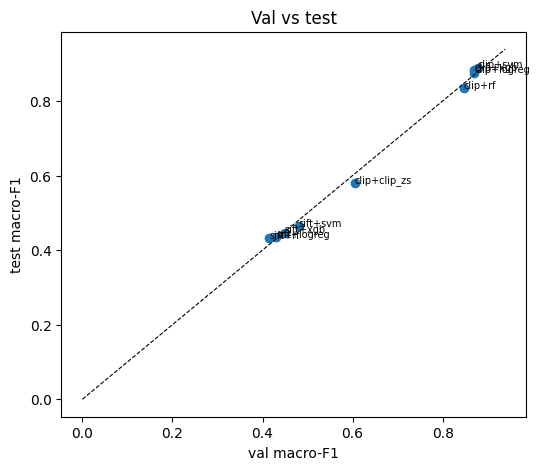

In [10]:
# Val có khớp test không? Điểm nằm xa đường chéo = chọn mô hình trên val chưa đáng tin
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(te.val_macro_f1, te.test_macro_f1)
for _, r in te.iterrows(): ax.annotate(f'{r.feature}+{r.model}', (r.val_macro_f1, r.test_macro_f1), fontsize=7)
lim = [0, max(te.val_macro_f1.max(), te.test_macro_f1.max()) + 0.05]
ax.plot(lim, lim, 'k--', lw=0.8); ax.set_xlabel('val macro-F1'); ax.set_ylabel('test macro-F1'); ax.set_title('Val vs test')

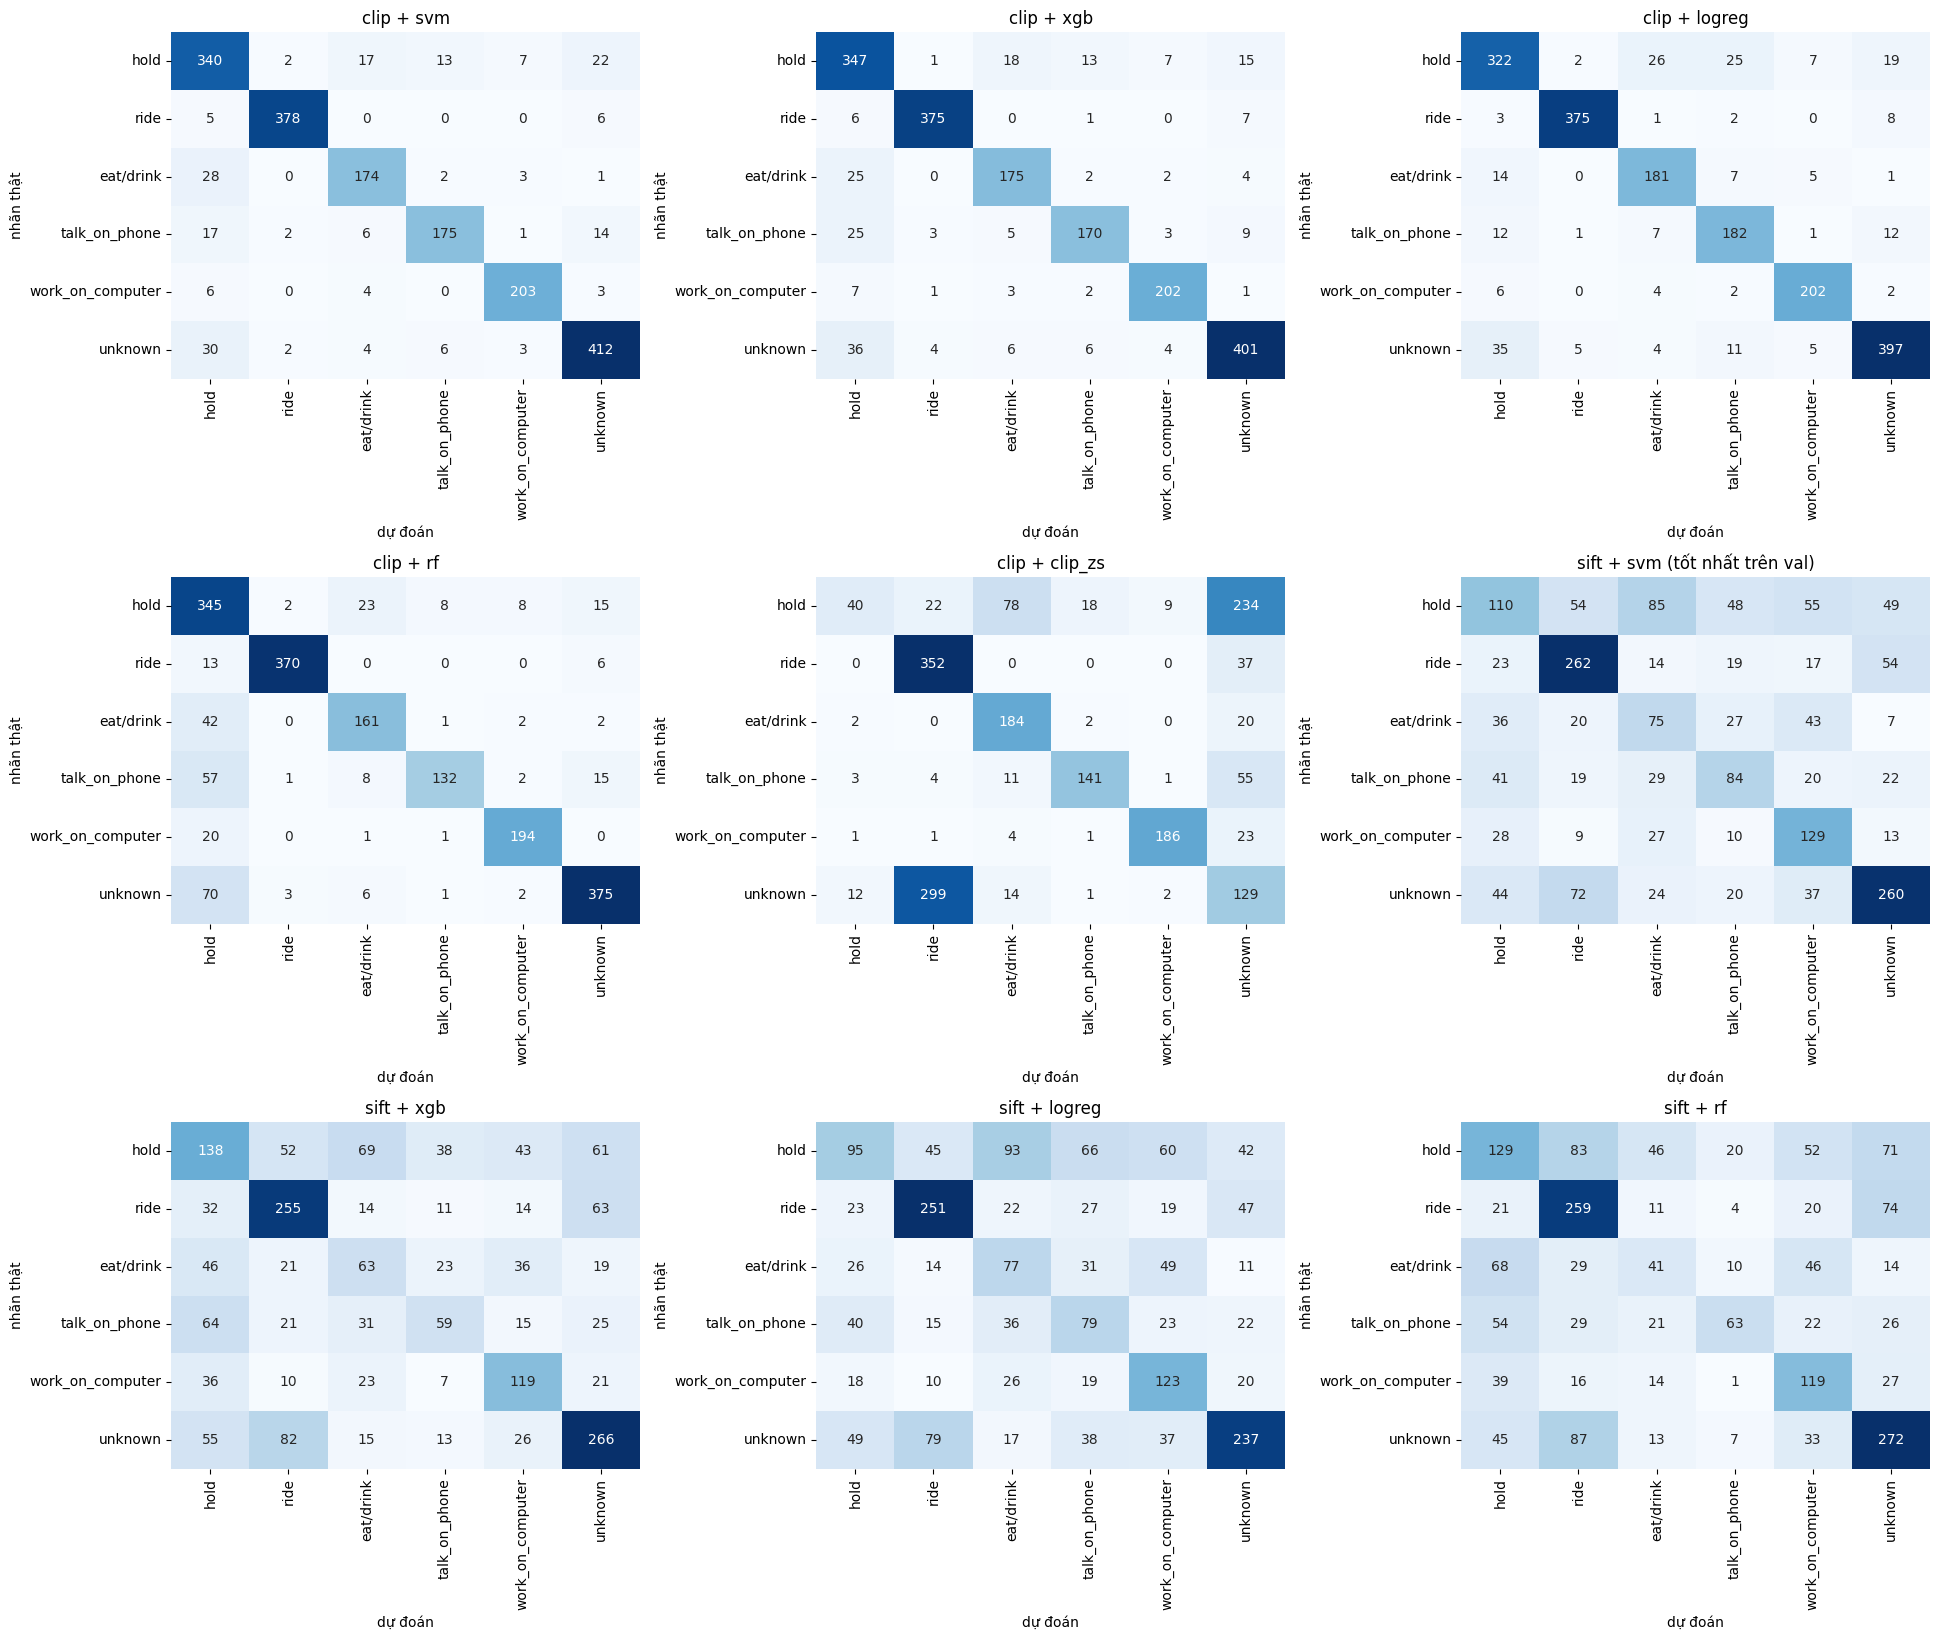

In [11]:
# Ma trận nhầm lẫn (số đếm; hàng = nhãn thật, cột = dự đoán) của mọi cấu hình đã test
from sklearn.metrics import confusion_matrix
# Cấu hình tốt nhất trên val của nhóm đặc trưng thủ công (dùng cho phân tích lỗi bên dưới)
best = te[te.is_best_on_val].sort_values('group', key=lambda g: g != 'handcrafted').iloc[0]   # ưu tiên nhóm thủ công
ncol = min(3, len(preds)); nrow = -(-len(preds) // ncol)
fig, axes = plt.subplots(nrow, ncol, figsize=(6.5 * ncol, 5.5 * nrow), squeeze=False)
for ax, ((f, m), p) in zip(axes.flat, preds.items()):
    cm = pd.DataFrame(confusion_matrix(yte, p, labels=range(len(C.CLASSES))), index=C.CLASSES, columns=C.CLASSES)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax)
    ax.set_xlabel('dự đoán'); ax.set_ylabel('nhãn thật')
    ax.set_title(f'{f} + {m}' + (' (tốt nhất trên val)' if (f, m) == (best.feature, best.model) else ''))
for ax in axes.flat[len(preds):]: ax.axis('off')
plt.tight_layout()

## 5. Thời gian chạy và tài nguyên

Nguồn: `data/features/<fXX>/timing_extract.csv` (bước 1), cột thời gian trong `val_results.csv` (bước 2) và `test_results.csv` (bước 3), `run_info.json` (tổng thời gian mỗi bước).

Tài nguyên (từ `r03` / `f03`, đo bằng `code/resources.py`): `peak_rss_mb` = RAM đỉnh của cả cây tiến trình (gồm worker joblib, là cận trên vì đếm trùng bộ nhớ dùng chung), `peak_delta_mb` = phần tăng thêm so với lúc bắt đầu đoạn đó, `cpu_util` = số nhân dùng trung bình. Dung lượng đặc trưng và kích thước mô hình đọc trực tiếp từ file nên có cho mọi phiên bản.

,bước,lệnh,thời điểm,tổng thời gian (s),ghi chú
0,01_extract_features,01_extract_features.py --version f03 --note f0...,2026-10-24T23:18:12,400.6,f02 + khối CLIP ViT-B/32; clip (zero-shot clip...
1,02_train_select,02_train_select.py --feat_version f03 --versio...,2026-10-24T23:25:47,453.3,f02 + khối CLIP ViT-B/32; clip (zero-shot clip...
2,03_final_test,03_final_test.py --version r04,2026-10-24T23:26:52,62.8,


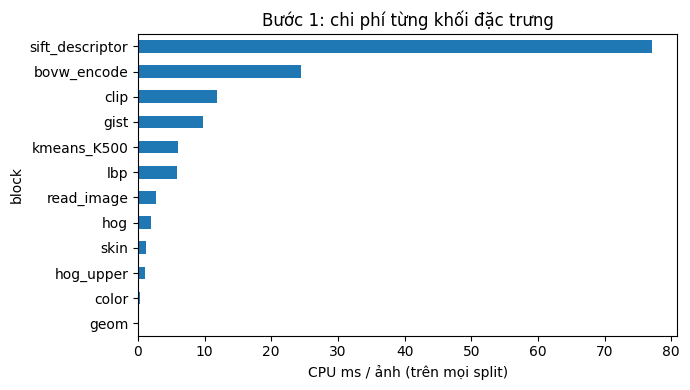

In [12]:
info = V.read_run_info(RES_DIR)
finfo = V.read_run_info(FEAT_DIR)
steps = {'01_extract_features': finfo, '02_train_select': info, '03_final_test': info}
display(pd.DataFrame([{'bước': k, 'lệnh': v[k][-1].get('command'), 'thời điểm': v[k][-1].get('time'),
                       'tổng thời gian (s)': v[k][-1].get('total_wall_s'), 'ghi chú': v[k][-1].get('note')}
                      for k, v in steps.items() if k in v]))
tx = pd.read_csv(FEAT_DIR / 'timing_extract.csv')
n_all = tx.drop_duplicates('split').n_images.sum()
blk = tx.groupby('block').cpu_s.sum().sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
(1000 * blk / n_all).plot.barh(ax=ax); ax.set_xlabel('CPU ms / ảnh (trên mọi split)')
ax.set_title('Bước 1: chi phí từng khối đặc trưng')
plt.tight_layout()

,n_grid,grid_search_s,fit_best_s
model,,,
clip_zs,6,0.3,0.0
logreg,8,3.8,0.5
rf,16,120.8,10.7
svm,18,140.5,12.4
xgb,16,137.5,23.0


,feature,model,dim,fit_s,predict_s,predict_ms_per_img
0,clip,svm,512,4.93,1.467,0.778
1,clip,xgb,512,17.11,0.015,0.008
2,clip,logreg,512,0.43,0.003,0.002
3,clip,rf,512,10.16,0.040,0.021
4,clip,clip_zs,512,0.00,0.001,0.000
5,sift,svm,500,12.98,2.930,1.554
6,sift,xgb,500,8.58,0.014,0.007
7,sift,logreg,500,0.22,0.004,0.002
8,sift,rf,500,2.59,0.064,0.034


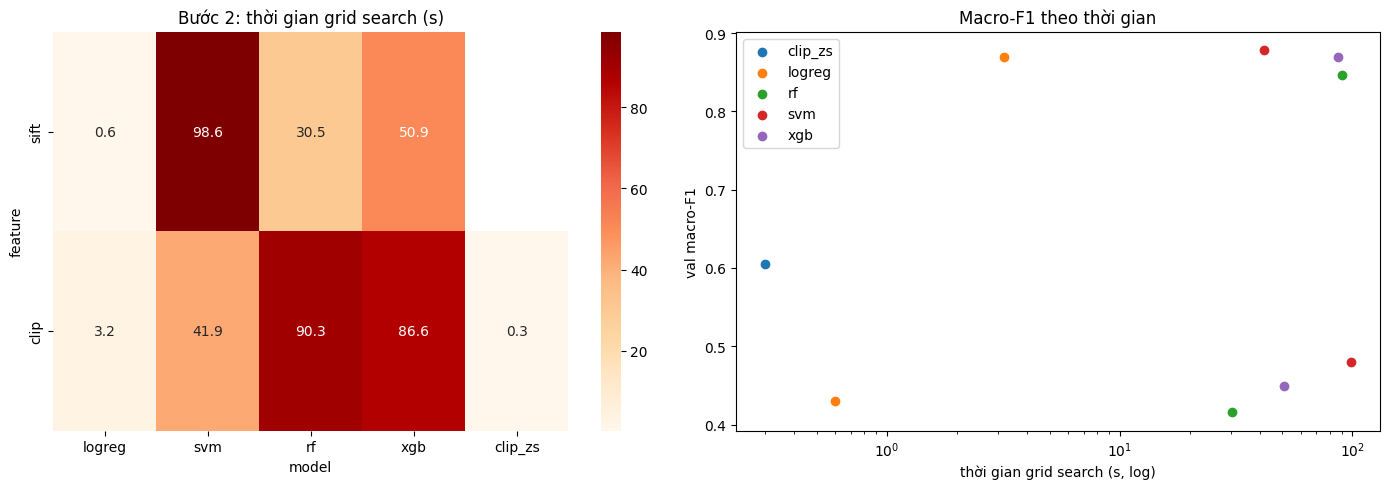

In [13]:
# Bước 2: thời gian grid search theo bộ đặc trưng x mô hình, và quan hệ macro-F1 - thời gian
if 'grid_search_s' in val:
    tp = val.pivot(index='feature', columns='model', values='grid_search_s').reindex([f for f in FEATURE_SETS if f in set(val.feature)])
    tp = tp[[m for m in ['logreg', 'svm', 'rf', 'xgb', 'clip_zs'] if m in tp.columns]]
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    sns.heatmap(tp, annot=True, fmt='.1f', cmap='OrRd', ax=axes[0]); axes[0].set_title('Bước 2: thời gian grid search (s)')
    for m, g in val.groupby('model'):
        axes[1].scatter(g.grid_search_s, g.val_macro_f1, label=m)
    axes[1].set_xscale('log'); axes[1].set_xlabel('thời gian grid search (s, log)'); axes[1].set_ylabel('val macro-F1')
    axes[1].legend(); axes[1].set_title('Macro-F1 theo thời gian')
    plt.tight_layout()
    display(val.groupby('model')[['n_grid', 'grid_search_s', 'fit_best_s']].sum().round(1))
else:
    print('Phiên bản này chưa có cột thời gian của bước 2.')
if 'fit_s' in te:
    display(te[['feature', 'model', 'dim', 'fit_s', 'predict_s', 'predict_ms_per_img']].round(3))

,bước,total_wall_s,peak_rss_mb,peak_delta_mb,cpu_s,cpu_util,disk_mb
0,01_extract_features,400.6,4008.2,3832.9,2660.1,6.64,585.5
1,02_train_select,453.3,4864.1,4715.0,2769.5,6.11,NaN
2,03_final_test,62.8,864.8,689.7,272.0,4.33,261.4


Máy: {'platform': 'macOS-26.6.2-arm64-arm-64bit', 'machine': 'arm64', 'cpu_logical': 10, 'cpu_physical': 10, 'ram_total_gb': 25.8, 'python': '3.9.6', 'packages': {'numpy': '2.0.2', 'scikit-learn': '1.6.1', 'xgboost': '2.1.4', 'opencv-python': '5.0.0.93', 'psutil': '7.2.2'}}


,feature,model,dim,X_mb,peak_rss_mb,peak_delta_mb,cpu_util,time_s
1,clip,xgb,512,22.4,4864.1,665.7,5.69,102.1
6,sift,xgb,500,21.9,4746.2,706.2,5.53,58.5
8,sift,rf,500,21.9,4617.0,965.1,6.43,32.6
7,sift,logreg,500,21.9,4524.9,224.2,2.18,0.8
5,sift,svm,500,21.9,4506.8,569.8,6.49,109.5
3,clip,rf,512,22.4,4295.3,353.2,6.72,99.0
4,clip,clip_zs,512,22.4,4255.0,111.4,0.86,0.3
0,clip,svm,512,22.4,3942.1,2500.8,5.67,46.9
2,clip,logreg,512,22.4,1440.8,1224.0,3.17,3.5


,feature,model,X_mb,peak_rss_mb,peak_delta_mb,model_mb,fit_s,predict_ms_per_img
0,clip,svm,22.4,501.4,249.6,23.895,4.93,0.778
1,clip,xgb,22.4,554.1,16.6,5.678,17.11,0.008
2,clip,logreg,22.4,664.2,45.9,0.038,0.43,0.002
3,clip,rf,22.4,681.8,16.5,69.210,10.16,0.021
4,clip,clip_zs,22.4,635.2,0.0,0.011,0.00,0.000
5,sift,svm,21.9,820.9,163.2,41.451,12.98,1.554
6,sift,xgb,21.9,825.8,44.9,5.496,8.58,0.007
7,sift,logreg,21.9,818.8,0.3,0.037,0.22,0.002
8,sift,rf,21.9,854.0,34.3,114.644,2.59,0.034


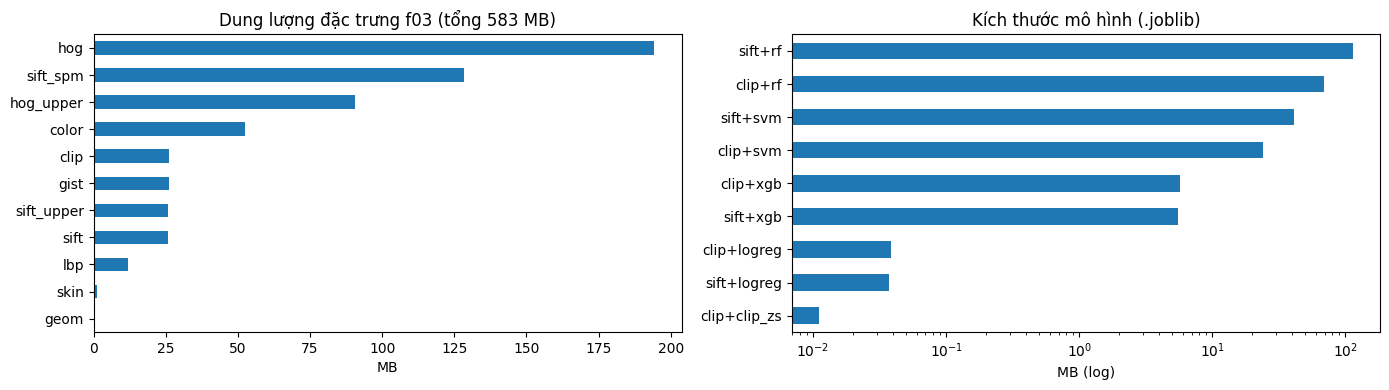

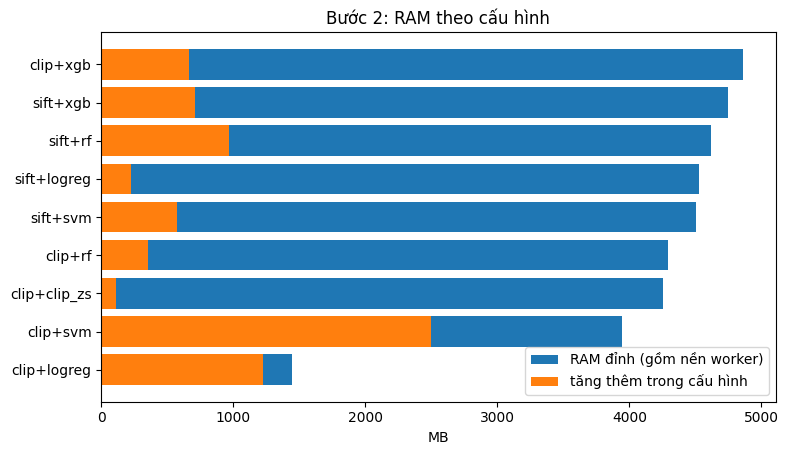

In [14]:
# Tài nguyên: RAM, dung lượng đĩa, kích thước mô hình
steps_res = pd.DataFrame([{'bước': k, **{c: v[k][-1].get(c) for c in ['total_wall_s', 'peak_rss_mb', 'peak_delta_mb', 'cpu_s', 'cpu_util', 'disk_mb']}}
                          for k, v in steps.items() if k in v])
display(steps_res)
mi = next((v[k][-1]['machine_info'] for k, v in steps.items() if k in v and 'machine_info' in v[k][-1]), None)
print('Máy:', mi if mi else 'phiên bản này chưa ghi machine_info')

# Dung lượng đặc trưng trên đĩa theo khối (cả 3 split) và kích thước mô hình đã lưu: đọc thẳng từ file
disk = pd.Series({b: sum((FEAT_DIR / f'{s}_{b}.npy').stat().st_size for s in C.SPLITS if (FEAT_DIR / f'{s}_{b}.npy').exists()) / 1e6
                  for b in C.ATOMIC_FEATURES + C.CLIP_FEATURES}).loc[lambda s: s > 0].sort_values()
msize = pd.Series({f'{r.feature}+{r.model}': (RES_DIR / 'models' / f'{r.feature}_{r.model}.joblib').stat().st_size / 1e6
                   for r in te.itertuples() if (RES_DIR / 'models' / f'{r.feature}_{r.model}.joblib').exists()}).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
disk.plot.barh(ax=axes[0]); axes[0].set_xlabel('MB'); axes[0].set_title(f'Dung lượng đặc trưng {FEAT_DIR.name} (tổng {disk.sum():.0f} MB)')
msize.plot.barh(ax=axes[1], logx=True); axes[1].set_xlabel('MB (log)'); axes[1].set_title('Kích thước mô hình (.joblib)')
plt.tight_layout()

# RAM theo cấu hình (chỉ có từ r03)
if 'peak_rss_mb' in val:
    order = val.sort_values('peak_rss_mb').assign(cfg=lambda d: d.feature + '+' + d.model)
    fig, ax = plt.subplots(figsize=(8, 0.35 * len(order) + 1.5))
    ax.barh(order.cfg, order.peak_rss_mb, label='RAM đỉnh (gồm nền worker)')
    ax.barh(order.cfg, order.peak_delta_mb, label='tăng thêm trong cấu hình')
    ax.set_xlabel('MB'); ax.set_title('Bước 2: RAM theo cấu hình'); ax.legend(); plt.tight_layout()
    display(val[['feature', 'model', 'dim', 'X_mb', 'peak_rss_mb', 'peak_delta_mb', 'cpu_util', 'time_s']].sort_values('peak_rss_mb', ascending=False))
else:
    print('Phiên bản này chưa đo RAM ở bước 2 (có từ r03).')
if 'peak_rss_mb' in te:
    display(te[['feature', 'model', 'X_mb', 'peak_rss_mb', 'peak_delta_mb', 'model_mb', 'fit_s', 'predict_ms_per_img']])


## 6. Phân tích lỗi

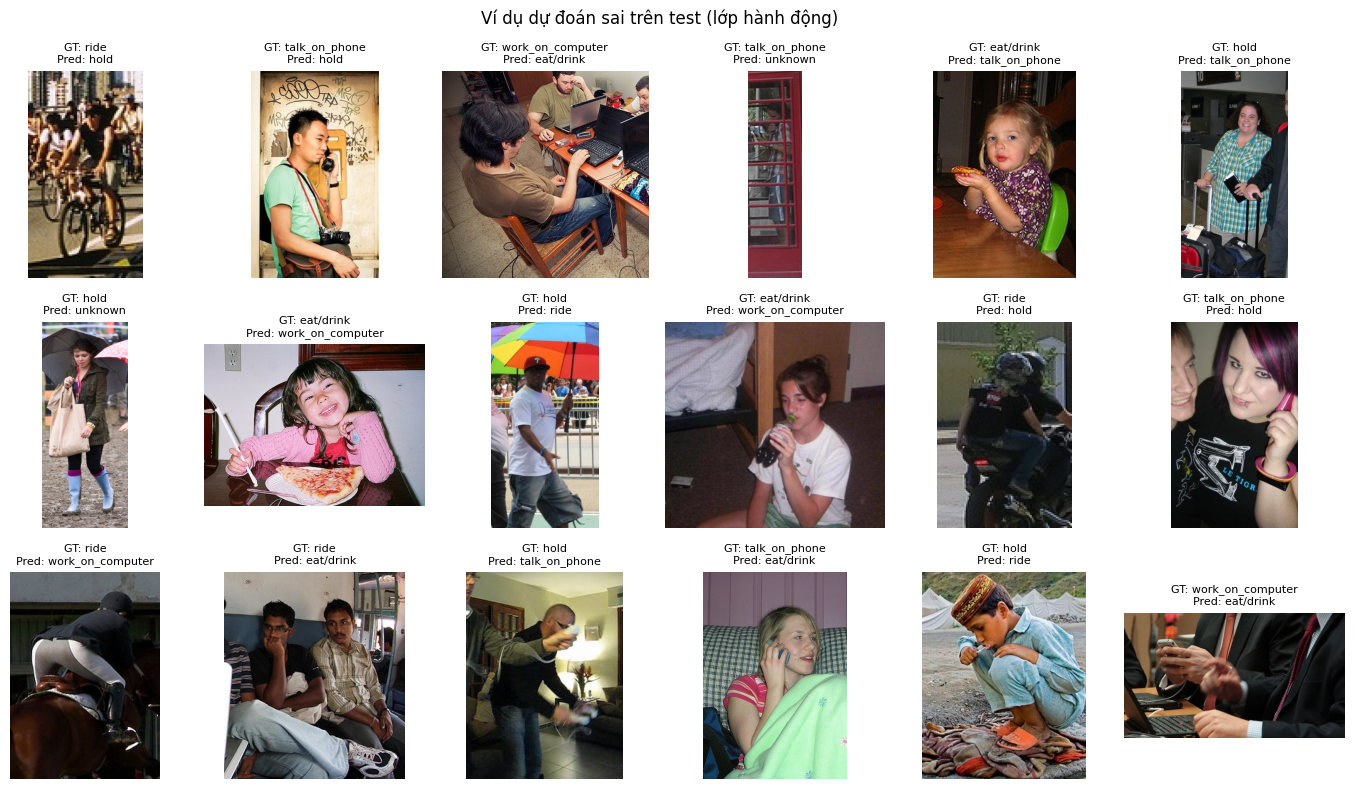

In [15]:
meta = pd.read_csv(FEAT_DIR / 'meta_test.csv')
pred = np.load(RES_DIR / f'test_pred_{best.feature}_{best.model}.npy')
meta['pred'] = [C.CLASSES[p] for p in pred]
wrong = meta[(meta.label != meta.pred) & (meta.label != 'unknown')]
fig, axes = plt.subplots(3, 6, figsize=(14, 8))
for ax, (_, r) in zip(axes.flat, wrong.sample(min(18, len(wrong)), random_state=1).iterrows()):
    ax.imshow(cv2.cvtColor(read_image(str(C.DATA_DIR / r.crop_path)), cv2.COLOR_BGR2RGB))
    ax.set_title(f'GT: {r.label}\nPred: {r.pred}', fontsize=8)
for ax in axes.flat: ax.axis('off')
plt.suptitle('Ví dụ dự đoán sai trên test (lớp hành động)'); plt.tight_layout()

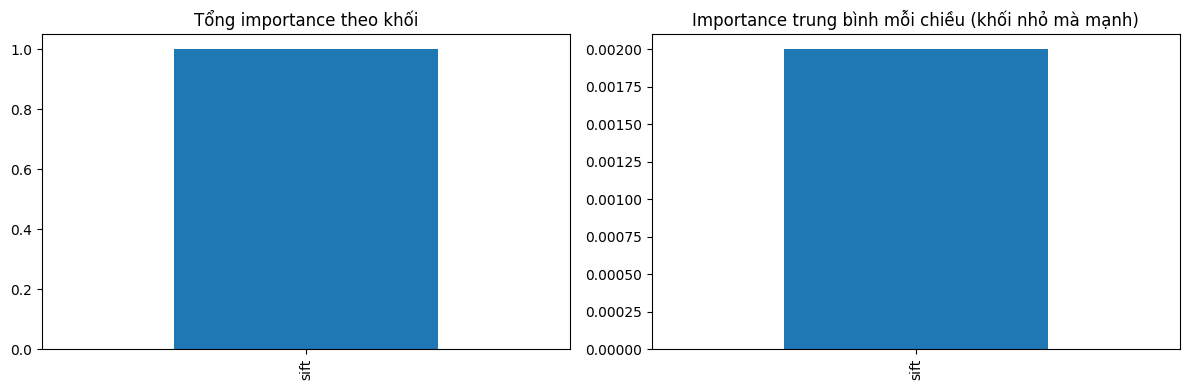

In [16]:
# Độ quan trọng theo khối đặc trưng: RF (không PCA) train trên train, nối các khối của mọi bộ đặc trưng đã chạy ở bước 2
from sklearn.ensemble import RandomForestClassifier
# Chỉ các khối đặc trưng thủ công (CLIP là mốc so sánh, không đưa vào đây)
bl = list(dict.fromkeys(b for f in FEATURE_SETS if f in set(val.feature) for b in blocks(f) if b not in C.CLIP_FEATURES))
if not bl:
    print('Phiên bản này không có khối đặc trưng thủ công.')
else:
    Xtr = np.hstack([np.load(FEAT_DIR / f'train_{b}.npy') for b in bl]); ytr = np.load(FEAT_DIR / 'y_train.npy')
    rf = RandomForestClassifier(500, class_weight='balanced_subsample', n_jobs=-1, random_state=C.SEED).fit(Xtr, ytr)
    dims = [np.load(FEAT_DIR / f'train_{b}.npy', mmap_mode='r').shape[1] for b in bl]
    imp = np.split(rf.feature_importances_, np.cumsum(dims)[:-1])
    imp_df = pd.DataFrame({'tổng': [v.sum() for v in imp], 'trung bình / chiều': [v.mean() for v in imp]}, index=bl)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    imp_df['tổng'].plot.bar(ax=axes[0], title='Tổng importance theo khối')
    imp_df['trung bình / chiều'].plot.bar(ax=axes[1], title='Importance trung bình mỗi chiều (khối nhỏ mà mạnh)')
    plt.tight_layout()

## 7. Nhận xét gợi ý
- `ride`: crop chỉ chứa ~47% diện tích vật (ngựa/xe) → cần bối cảnh (`gist`, `color`) và dáng ngồi (`geom`, HOG).
- `talk_on_phone`, `eat/drink`: vật nhỏ ở gần đầu → `upper` và `sift_spm` được thiết kế cho trường hợp này.
- `geom` chỉ 8 chiều nhưng mang thông tin tỉ lệ khung/vị trí mà các đặc trưng ảnh (đã resize) làm mất.
- Mọi lựa chọn siêu tham số dựa trên val; test chỉ được dùng để báo cáo. Nếu val nhỏ, biểu đồ val-vs-test cho thấy việc chọn mô hình còn nhiễu.